# Tabula muris senis: lung (droplet)


In this notebook we:
* Load TMS lung droplet dataset
* Preprocessing and normalization
* Create two annData objects: `adata_young` and `adata_old`
* Create table with cell type composition in young and old samples.
* Downsampling of counts so that the young and the old dataset have a comparable number of counts/cell
* Downsampling of cells so that the young and the old dataset have the same amount of cells per cell type
* Write the two annData objects


**INPUT**:
* `tabula-muris-senis-droplet-processed-official-annotations-Lung.h5ad` 


**OUTPUT**: 
* `TMS_lung_droplet_young_annotated.h5ad` and `TMSlung_droplet_old_annotated.h5ad`: both annData objects are preprocessed, cell-type annotated, downsampled and ready for the Scallop analysis.
* `TMS_lung_droplet_DEGs_per_ct.csv`: DEGs per cell type
* `TMS_lung_droplet_cell_type_composition.csv`: table with cell-type composition

In [1]:
import os
import sys

# Data analysis & stats
import pandas as pd
import numpy as np
from scipy.stats import ranksums
from scipy.sparse import csr_matrix

# Single-cell
import scanpy as sc
import scanpy.external as sce
import anndata

# Cell type annotation
sys.path.append('../../scoreCT/src/')
import scorect_api as ct

# Plotting & palettes
import matplotlib.pyplot as plt
import seaborn as sns
from palettable.cartocolors.qualitative import Pastel_10, Safe_10, Bold_10, Vivid_10, Prism_10, Antique_5
from palettable.colorbrewer.qualitative import Set3_12


seed=10
name_dataset = 'TMS_lung_droplet'

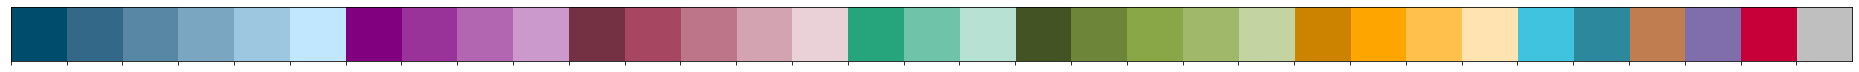

In [2]:
mypal = pd.read_csv('../../data/palettes/Cell_type_palette.csv', index_col=0)['color_manual']
mypal_dic = dict(mypal)
sns.palplot(mypal.values.tolist())

In [3]:
cell_type_colors = dict(pd.read_csv('../../data/palettes/Cell_type_palette.csv', index_col=0)['color_manual'])
cell_types_sorted = pd.read_csv('../../data/palettes/Cell_type_palette.csv', index_col=0)['color_manual'].index
ct_order = {ct: i for i, ct in enumerate(cell_types_sorted)}
# sns.palplot(mypal)

# Load dataset & metadata

In [4]:
adata_all = sc.read('../../data/raw_data/tms_droplet/tabula-muris-senis-droplet-processed-official-annotations-Lung.h5ad')

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/compat/__init__.py:161: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  FutureWarning,
/home/amon/anaconda3/lib/python3.7/site-packages/anndata/compat/__init__.py:161: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  FutureWarning,


In [5]:
adata = adata_all[adata_all.obs['age'].isin(['3m', '30m'])]

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1094: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if not is_categorical(df_full[k]):


In [6]:
sc.pp.calculate_qc_metrics(adata, inplace=True)

Trying to set attribute `.obs` of view, copying.


In [7]:
adata

AnnData object with n_obs × n_vars = 14705 × 20138
    obs: 'age', 'cell', 'cell_ontology_class', 'cell_ontology_id', 'free_annotation', 'method', 'mouse.id', 'n_genes', 'sex', 'subtissue', 'tissue', 'tissue_free_annotation', 'n_counts', 'louvain', 'leiden', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes'
    var: 'n_cells', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'age_colors', 'cell_ontology_class_colors', 'leiden', 'louvain', 'neighbors', 'pca'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

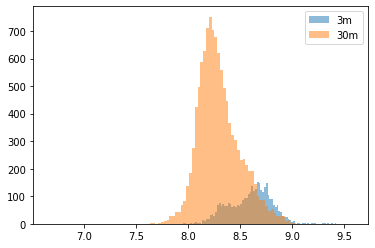

In [8]:
h = plt.hist(adata[adata.obs['age'] == '3m'].obs['log1p_total_counts'], label='3m', bins=100, alpha=0.5)
h = plt.hist(adata[adata.obs['age'] == '30m'].obs['log1p_total_counts'], label='30m', bins=100, alpha=0.5)
plt.legend()
plt.savefig('../../output/figs/supplementary/tms_droplet/3m_vs_30m_logtotal_counts.svg')
plt.savefig('../../output/figs/supplementary/tms_droplet/3m_vs_30m_logtotal_counts.png', dpi=400)

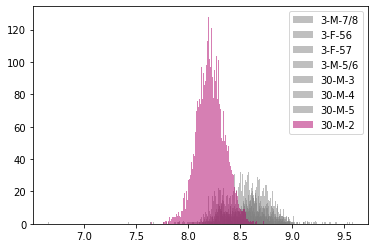

In [9]:
m = '30-M-2'
for mouse in set(adata.obs['mouse.id']):
    if mouse == m: color = '#af0069'
    else: color = 'grey'
    h = plt.hist(adata[adata.obs['mouse.id'] == mouse].obs['log1p_total_counts'], label=mouse, bins=300, alpha=0.5, color=color)
plt.legend()
plt.savefig('../../output/figs/supplementary/tms_droplet/30-M-2_vs_rest.svg')
plt.savefig('../../output/figs/supplementary/tms_droplet/30-M-2_vs_rest.png', dpi=400)

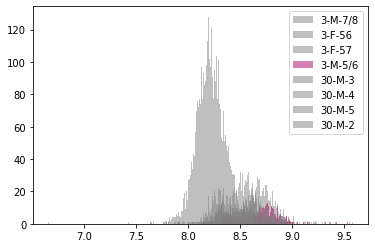

In [10]:
m = '3-M-5/6'
for mouse in set(adata.obs['mouse.id']):
    if mouse == m: color = '#af0069'
    else: color = 'grey'
    h = plt.hist(adata[adata.obs['mouse.id'] == mouse].obs['log1p_total_counts'], label=mouse, bins=300, alpha=0.5, color=color)
plt.legend()
plt.savefig('../../output/figs/supplementary/tms_droplet/3-M-56_vs_rest.svg')
plt.savefig('../../output/figs/supplementary/tms_droplet/3-M-56_vs_rest.png', dpi=400)

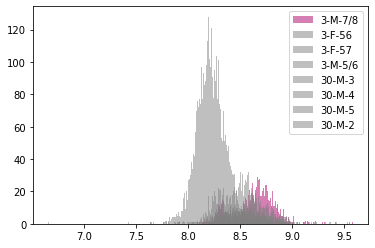

In [11]:
m = '3-M-7/8'
for mouse in set(adata.obs['mouse.id']):
    if mouse == m: color = '#af0069'
    else: color = 'grey'
    h = plt.hist(adata[adata.obs['mouse.id'] == mouse].obs['log1p_total_counts'], label=mouse, bins=300, alpha=0.5, color=color)
plt.legend()
plt.savefig('../../output/figs/supplementary/tms_droplet/3-M-78_vs_rest.svg')
plt.savefig('../../output/figs/supplementary/tms_droplet/3-M-78_vs_rest.png', dpi=400)

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1192: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if is_string_dtype(df[key]) and not is_categorical(df[key])


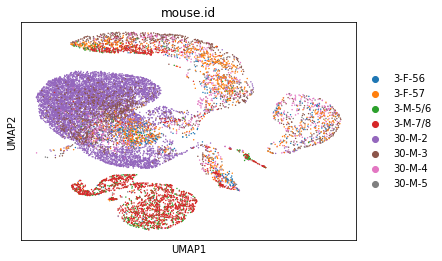

In [12]:
sc.pl.umap(adata, color=['mouse.id'])

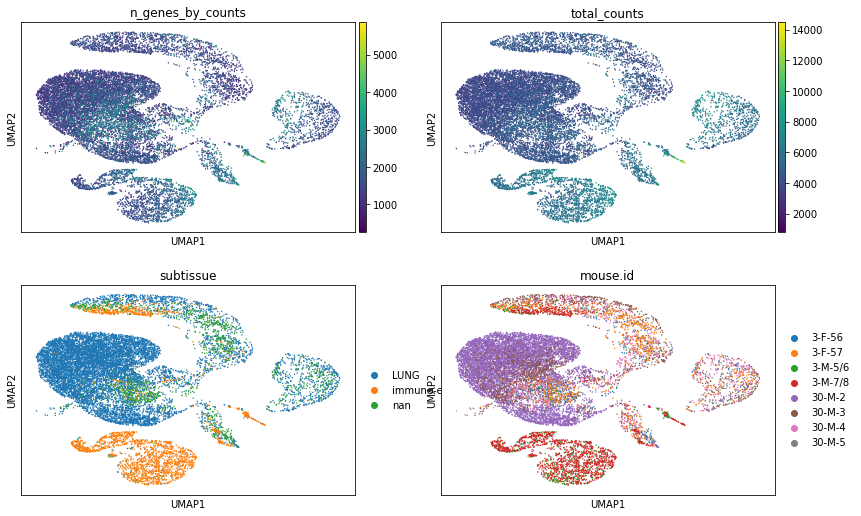

In [14]:
sc.pl.umap(adata, color=['n_genes_by_counts', 'total_counts', 'subtissue', 'mouse.id' ], ncols=2)

In [15]:
# Discard cells from sample 30-M-2 because they have very few counts/cell compared to the rest of the samples
adata = adata[adata.obs['mouse.id'] != '30-M-2']
adata = adata[adata.obs['mouse.id'] != '3-M-5/6']
adata = adata[adata.obs['mouse.id'] != '3-M-7/8']

In [16]:
for mouse in set(adata.obs['mouse.id']):
    print(mouse, np.sum(adata[adata.obs['mouse.id']==mouse].X)/adata[adata.obs['mouse.id']==mouse].shape[0])

3-F-56 5389.114986187846
3-F-57 4937.652347652348
30-M-3 4752.35347985348
30-M-4 5458.0699786324785
30-M-5 5093.494059405941


# Normalization & preprocessing

In [18]:
def normalization(adata):
    sc.pp.filter_cells(adata, min_genes=200)
    sc.pp.filter_genes(adata, min_cells=3)
    sc.pp.calculate_qc_metrics(adata, inplace=True)
#     adata = adata[adata.obs['total_counts'] > 800]
    adata.var_names_make_unique()
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
#     sc.pp.regress_out(adata, ['total_counts'])
    return adata

In [19]:
def preprocessing(adata, batch_key):
    sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=8, min_disp=0.1)
    sc.pp.pca(adata)
    if batch_key is None:
        print('Batch key is None, computing neighbors')
        sc.pp.neighbors(adata)
    else: 
        print(f'Using {batch_key} as batch_key to compute bbknn')
        sce.pp.bbknn(adata, batch_key=batch_key)
    sc.tl.umap(adata)
    # sc.tl.tsne(adata)
    return adata

In [20]:
adata = normalization(adata)

Trying to set attribute `.obs` of view, copying.


In [21]:
adata = preprocessing(adata, batch_key='mouse.id')

Using mouse.id as batch_key to compute bbknn


/home/amon/anaconda3/lib/python3.7/site-packages/bbknn/__init__.py:289: FutureWarning: This location for 'distances' is deprecated. It has been moved to .obsp[distances], and will not be accesible here in a future version of anndata.
  adata.uns['neighbors']['distances'] = bbknn_out[0]
/home/amon/anaconda3/lib/python3.7/site-packages/bbknn/__init__.py:290: FutureWarning: This location for 'connectivities' is deprecated. It has been moved to .obsp[connectivities], and will not be accesible here in a future version of anndata.
  adata.uns['neighbors']['connectivities'] = bbknn_out[1]


## UMAP: cell type annotations

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1192: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if is_string_dtype(df[key]) and not is_categorical(df[key])


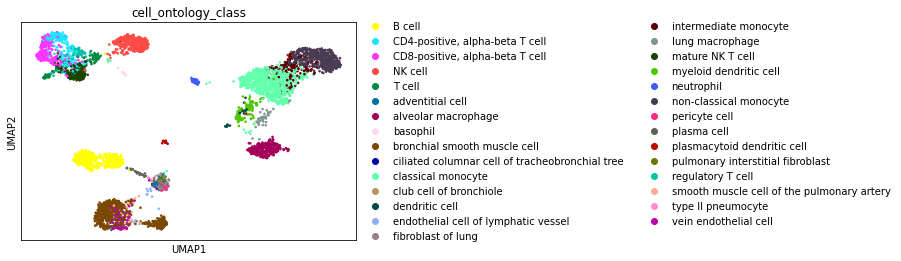

In [22]:
sc.pl.umap(adata, color=['cell_ontology_class'], ncols=1)

## UMAP: mouse

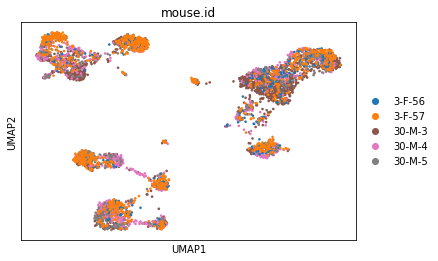

In [23]:
sc.pl.umap(adata, color=[ 'mouse.id'])

## UMAP: age

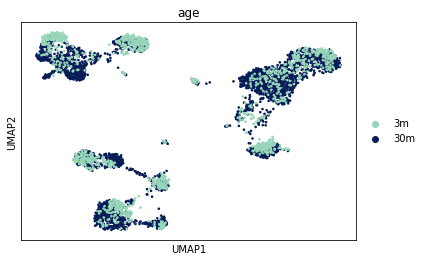

In [24]:
sc.pl.umap(adata, color=['age'])

# Cell-type annotation

Even though Tabula muris senis data was automatically annotated, in the present work we annotated by projecting the cell type labels used by Angelidis. This way we obtained comparable annotations of the main lung cell types. We predict cell type labels based on the the Tabula muris senis lung dataset by using the CTscore software with the DEGs between the cell types in the Angelidis dataset. 

In [25]:
ref_marker = pd.read_csv('../../output/tables/Angelidis_ct_markers.csv', index_col=0).iloc[0:300, :]

In [26]:
sc.tl.leiden(adata, random_state=seed, resolution=4.5)

In [27]:
len(set(adata.obs['leiden']))

33

In [28]:
sc.tl.rank_genes_groups(adata, groupby='leiden', use_raw=True)

In [29]:
marker_df = ct.wrangle_ranks_from_anndata(adata)

Wrangling: Number of markers used in ranked_gene_groups:  20138
Wrangling: Groups used for ranking: leiden


In [30]:
# Score cell types for each cluster 
# Let's set parameters first - K represents the number of genes included in the ranking
# m represents the number of bins used to divide the top K genes.
K = 300
m = 5
# Get the background genes - here, all the genes used to run the differential gene expression test
background = adata.var_names.tolist()
# Now run the function
ct_pval, ct_score = ct.celltype_scores(nb_bins=m,
                                        ranked_genes=marker_df,
                                        K_top = K,
                                        marker_ref=ref_marker,
                                        background_genes=background)

In [31]:
# Now assign clusters to cell types
cluster_assign = adata.obs['leiden']
celltype_assign = ct.assign_celltypes(cluster_assignment=cluster_assign, ct_pval_df=ct_pval, ct_score_df=ct_score, cutoff=0.1)
# Add to anndata object
adata.obs['cell_type'] = celltype_assign

In [32]:
adata.obs_names

Index(['AAACCTGAGCATCATC-1-14-1-0', 'AAACCTGCATCCTAGA-1-14-1-0',
       'AAACCTGGTGAGGGAG-1-14-1-0', 'AAACCTGTCACTTCAT-1-14-1-0',
       'AAACGGGAGCGATATA-1-14-1-0', 'AAACGGGAGGTGCTAG-1-14-1-0',
       'AAACGGGCAGACGCTC-1-14-1-0', 'AAACGGGGTACATGTC-1-14-1-0',
       'AAACGGGTCAAGATCC-1-14-1-0', 'AAAGATGAGATGAGAG-1-14-1-0',
       ...
       '10X_P7_9_TTTGCGCAGTATCGAA-1', '10X_P7_9_TTTGCGCTCAGCATGT-1',
       '10X_P7_9_TTTGGTTCACGAGAGT-1', '10X_P7_9_TTTGGTTGTACAGCAG-1',
       '10X_P7_9_TTTGGTTGTCGCGGTT-1', '10X_P7_9_TTTGGTTGTCTGCCAG-1',
       '10X_P7_9_TTTGGTTGTGAACCTT-1', '10X_P7_9_TTTGGTTTCTAGAGTC-1',
       '10X_P7_9_TTTGTCACATGCCCGA-1', '10X_P7_9_TTTGTCATCGGAGGTA-1'],
      dtype='object', name='index', length=4442)

... storing 'cell_type' as categorical


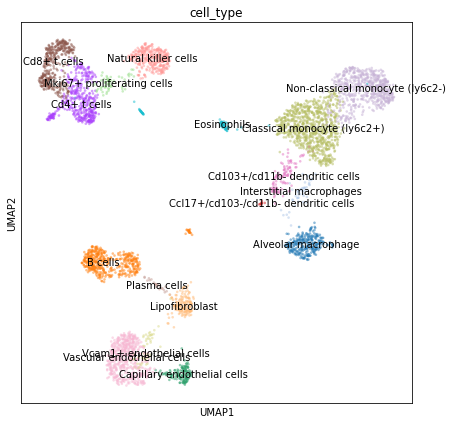

In [33]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 7))
sc.pl.umap(adata, ax=ax, color='cell_type', cmap='Set2', ncols=1, show=False, legend_loc='on data', alpha=0.5, legend_fontweight=10,  legend_fontsize=10)
plt.savefig('../../output/figs/supplementary/tms_droplet/UMAP_cell_types_predicted.svg')

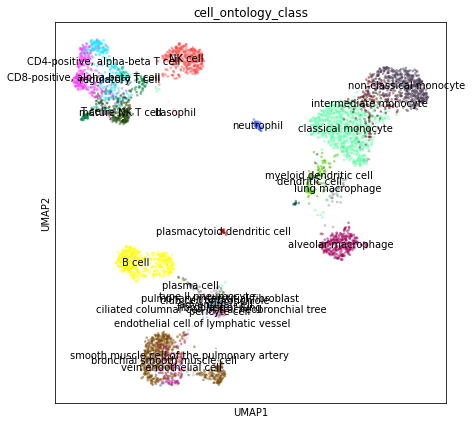

In [34]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(7, 7))
sc.pl.umap(adata, ax=ax, color=['cell_ontology_class'], cmap='Set2', ncols=1, show=False, legend_loc='on data', alpha=0.5, legend_fontweight=10,  legend_fontsize=10)
plt.savefig('../../output/figs/supplementary/tms_droplet/UMAP_cell_ontology_class.svg')

In [35]:
adata = adata[adata.obs['cell_type'] != 'NA']

/home/amon/anaconda3/lib/python3.7/site-packages/anndata/_core/anndata.py:1094: FutureWarning: is_categorical is deprecated and will be removed in a future version.  Use is_categorical_dtype instead
  if not is_categorical(df_full[k]):


We keep the samples at ages 3m and 24 months so that we can compare between the four lung datasets.

## Write adata_all

In [36]:
adata.write('../../data/anndatas/annotated/TMS_droplet_annotated.h5ad')

# Read h5ad

In [4]:
adata = sc.read_h5ad('../../data/anndatas/annotated/TMS_droplet_annotated.h5ad')

# Create two annData objects: young (3 month) and old (30 month)

In [5]:
# Create two annData objects for the young and old mice cells
adata_young = adata[adata.obs['age'] == '3m']
adata_old = adata[adata.obs['age'] == '30m']

#  Cell type composition in young and old cells

In [6]:
df_ct = pd.DataFrame(index=sorted(list(set(adata.obs['cell_type'])), reverse=True), columns=['Young', 'Old'])
for ct in set(adata.obs['cell_type']):
    df_ct.loc[ct, 'Young'] = adata_young[adata_young.obs['cell_type'] == ct].shape[0]
    df_ct.loc[ct, 'Old'] = adata_old[adata_old.obs['cell_type'] == ct].shape[0]
    
    df_ct.loc[ct, 'Young_perc'] = 100*adata_young[adata_young.obs['cell_type'] == ct].shape[0]/adata_young.shape[0]
    df_ct.loc[ct, 'Old_perc'] = 100*adata_old[adata_old.obs['cell_type'] == ct].shape[0]/adata_old.shape[0]

In [7]:
cell_types = sorted(list(set(adata.obs['cell_type'])))

In [8]:
cell_type_colors['Others'] = '#D3D3D3'

In [9]:
# pd.DataFrame.from_dict(data=cell_type_colors, orient='index', columns=['color']).to_csv('../data/angelidis/Angelidis_color_code.csv')

In [10]:
df_ct.sort_index(axis=0, key=lambda index_lst: [ct_order[ct] for ct in index_lst], inplace=True)

In [11]:
df_ct.to_csv('../../output/tables/ct_composition/TMS_lung_droplet_cell_type_composition.csv')

# Create input for enrichment analysis in R

In [12]:
age_dic = {'3m': 'Young', '24m': 'Old', '30m': 'Old', 'Young':'Young', 'Old': 'Old'}
adata.obs['age'] = [age_dic[age] for age in adata.obs['age']]

In [13]:
df_comp = pd.DataFrame()
mice = set(adata.obs['mouse.id'])
cell_types = set(adata.obs['cell_type'])

for mouse in mice:
    for ct in cell_types:
        count = adata[(adata.obs['mouse.id']==mouse) & (adata.obs['cell_type']==ct)].shape[0] # same mouse, same cell-type
        total = adata[adata.obs['mouse.id']==mouse].shape[0] # same mouse, all cell types
        other = total - count # same mouse, cell types other than ct
        
        # Fill in dataframe
        group_id = f'{ct}_{mouse}'
        
        df_comp.loc[group_id, 'Cell_type'] = ct
        df_comp.loc[group_id, 'Mouse'] = mouse
        df_comp.loc[group_id, 'Age'] = adata[adata.obs['mouse.id']==mouse].obs['age'][0] #it is impossible for the same mouse to have two different ages        
        df_comp.loc[group_id, 'Count'] = count
        df_comp.loc[group_id, 'Other'] = other
        df_comp.loc[group_id, 'Total'] = total
df_comp.to_csv('../../output/tables/cell_type_enrichment/input/TMS_droplet_input_for_enrichment.csv')

# Create input for enrichment analysis in R (only immune cells)

In [14]:
 immune_ct = pd.read_csv('../../data/palettes/cell_type_order.csv', index_col=0, names=['cell_type']).iloc[0:16,:].index

In [15]:
immune_ct

Index(['Cd4+ t cells', 'Cd8+ t cells', 'Natural killer cells',
       'Gamma-delta t cells', 'B cells', 'Plasma cells', 'Alveolar macrophage',
       'Non-classical monocyte (ly6c2-)', 'Interstitial macrophages',
       'Classical monocyte (ly6c2+)', 'Fn1+ macrophage',
       'Ccl17+/cd103-/cd11b- dendritic cells', 'Cd103+/cd11b- dendritic cells',
       'Cd209+/cd11b+ dendritic cells', 'Eosinophils', 'Neutrophils'],
      dtype='object', name='cell_type')

In [16]:
adata.obs['cell_type']

index
AAACCTGAGCATCATC-1-14-1-0        Classical monocyte (ly6c2+)
AAACCTGCATCCTAGA-1-14-1-0        Classical monocyte (ly6c2+)
AAACCTGGTGAGGGAG-1-14-1-0      Cd103+/cd11b- dendritic cells
AAACCTGTCACTTCAT-1-14-1-0                       Cd8+ t cells
AAACGGGAGCGATATA-1-14-1-0               Natural killer cells
                                           ...              
10X_P7_9_TTTGGTTGTCTGCCAG-1      Classical monocyte (ly6c2+)
10X_P7_9_TTTGGTTGTGAACCTT-1             Natural killer cells
10X_P7_9_TTTGGTTTCTAGAGTC-1                   Lipofibroblast
10X_P7_9_TTTGTCACATGCCCGA-1      Capillary endothelial cells
10X_P7_9_TTTGTCATCGGAGGTA-1                          B cells
Name: cell_type, Length: 4442, dtype: category
Categories (17, object): ['Alveolar macrophage', 'B cells', 'Capillary endothelial cells', 'Ccl17+/cd103-/cd11b- dendritic cells', ..., 'Non-classical monocyte (ly6c2-)', 'Plasma cells', 'Vascular endothelial cells', 'Vcam1+ endothelial cells']

In [17]:
adata_immune = adata[adata.obs['cell_type'].isin(immune_ct)]
adata_immune

View of AnnData object with n_obs × n_vars = 3534 × 15168
    obs: 'age', 'cell', 'cell_ontology_class', 'cell_ontology_id', 'free_annotation', 'method', 'mouse.id', 'n_genes', 'sex', 'subtissue', 'tissue', 'tissue_free_annotation', 'n_counts', 'louvain', 'leiden', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'cell_type'
    var: 'n_cells', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'age_colors', 'cell_ontology_class_colors', 'cell_type_colors', 'hvg', 'leiden', 'louvain', 'mouse.id_colors', 'neighbors', 'pca', 'rank_genes_groups', 'subtissue_colors', 'umap'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [20]:
adata_immune = preprocessing(adata_immune, batch_key=None)

Trying to set attribute `.uns` of view, copying.


Batch key is None, computing neighbors


... storing 'age' as categorical


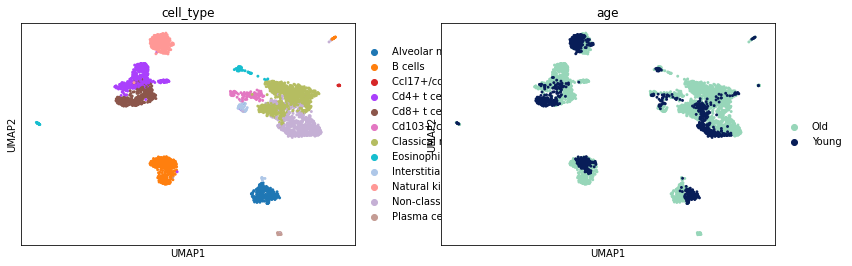

... storing 'age' as categorical


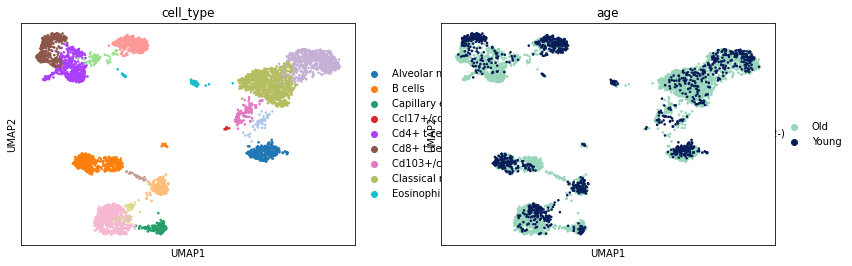

In [21]:
sc.pl.umap(adata_immune, color=['cell_type', 'age'])
sc.pl.umap(adata, color=['cell_type', 'age'])

In [24]:
df_comp = pd.DataFrame()
mice = set(adata_immune.obs['mouse.id'])
cell_types = set(adata_immune.obs['cell_type'])

for mouse in mice:
    for ct in cell_types:
        count = adata_immune[(adata_immune.obs['mouse.id']==mouse) & (adata_immune.obs['cell_type']==ct)].shape[0] # same mouse, same cell-type
        total = adata_immune[adata_immune.obs['mouse.id']==mouse].shape[0] # same mouse, all cell types
        other = total - count # same mouse, cell types other than ct
        
        # Fill in dataframe
        group_id = f'{ct}_{mouse}'
        
        df_comp.loc[group_id, 'Cell_type'] = ct
        df_comp.loc[group_id, 'Mouse'] = mouse
        df_comp.loc[group_id, 'Age'] = adata_immune[adata_immune.obs['mouse.id']==mouse].obs['age'][0] #it is impossible for the same mouse to have two different ages
        
        df_comp.loc[group_id, 'Count'] = count
        df_comp.loc[group_id, 'Other'] = other
        df_comp.loc[group_id, 'Total'] = total
df_comp.to_csv('../../output/tables/cell_type_enrichment/input/TMS_droplet_input_for_enrichment_immune.csv')

In [25]:
df_comp

,Cell_type,Mouse,Age,Count,Other,Total
Cd103+/cd11b- dendritic cells_30-M-5,Cd103+/cd11b- dendritic cells,30-M-5,Old,8.0,370.0,378.0
Eosinophils_30-M-5,Eosinophils,30-M-5,Old,10.0,368.0,378.0
Classical monocyte (ly6c2+)_30-M-5,Classical monocyte (ly6c2+),30-M-5,Old,59.0,319.0,378.0
B cells_30-M-5,B cells,30-M-5,Old,87.0,291.0,378.0
Alveolar macrophage_30-M-5,Alveolar macrophage,30-M-5,Old,22.0,356.0,378.0
Cd8+ t cells_30-M-5,Cd8+ t cells,30-M-5,Old,40.0,338.0,378.0
Interstitial macrophages_30-M-5,Interstitial macrophages,30-M-5,Old,6.0,372.0,378.0
Cd4+ t cells_30-M-5,Cd4+ t cells,30-M-5,Old,40.0,338.0,378.0
Non-classical monocyte (ly6c2-)_30-M-5,Non-classical monocyte (ly6c2-),30-M-5,Old,83.0,295.0,378.0
Plasma cells_30-M-5,Plasma cells,30-M-5,Old,0.0,378.0,378.0


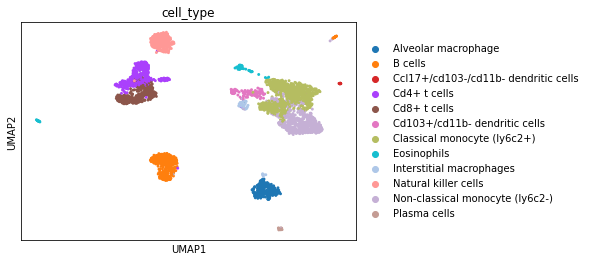

In [26]:
  sc.pl.umap(adata_immune, color='cell_type')

In [27]:
adata_immune.write('../../data/anndatas/immune/TMS_droplet_immune.h5ad')